# 08 - Original-source ROI preparation and error audit

Compare the old downsample-first pipeline with crop-first preparation from verified originals. This is a preprocessing hypothesis, not evidence of an accuracy gain. Preserve all 10,889 crop IDs, labels, groups and split assignments. Read train/validation images only. The output contains local views only because the next experiments do not use context.

```mermaid
flowchart LR
 A[Verified raw source and annotation] --> B[Identity and geometry checks]
 B --> C[Crop native pixels]
 C --> D[Resize once to 224 and save provenance]
 D --> E[Compare detail, class balance and errors]
```

Outputs: `data/processed/gum_raw_roi_v1/` and `docs/reports/raw_roi_preparation/`. No test pixels are opened; no clinical relabeling or quality-based case removal is performed.

## 1. Resolve paths and record the protocol

Find the actual project root and import the shared implementation. The implementation appendix below exposes the processing logic for thesis review.

In [1]:
from pathlib import Path
import sys, json, inspect, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/configs/roi.json').exists())
sys.path.insert(0, str(ROOT/'src'))
from dentalselfie.raw_roi import prepare_raw_rois
from dentalselfie import raw_roi
REPORT = ROOT/'docs/reports/raw_roi_preparation'
REPORT.mkdir(parents=True, exist_ok=True)
OLD_ROOT = ROOT/'data/processed/gum_roi_v1'
NEW_ROOT = ROOT/'data/processed/gum_raw_roi_v1'
old = pd.read_csv(OLD_ROOT/'manifest.csv')
print('Old ROI rows:',len(old), '| train/val only:', sorted(old.split.unique()))
display(old.groupby('split')[['box_width','box_height']].median())

Old ROI rows: 10889 | train/val only: ['train', 'val']


,box_width,box_height
split,,
train,100.17408,102.403140
val,99.47776,101.707984


## 2. Show the complete processing implementation

Verify source SHA-256, annotation mapping and order, EXIF policy, original dimensions and normalized-coordinate equivalence before extracting any crop. Preserve exact source provenance and inherited splits.

In [2]:
print(inspect.getsource(raw_roi))

"""Derive raw-source local ROIs with unchanged annotation identities and split locks."""
from __future__ import annotations

import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

from .acquire import digest
from .roi import pixel_box, view_bounds, padded_view


def retained_annotations(text, mapping):
    rows = []
    for line_index, line in enumerate(text.splitlines()):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != 5 or fields[0] not in mapping:
            raise ValueError(f"Unknown source annotation at line {line_index}")
        if mapping[fields[0]] is not None:
            rows.append((line_index, mapping[fields[0]], list(map(float, fields[1:]))))
    return rows


def prepare_raw_rois(root: Path, workers=2):
    root = Path(root)
    old_root = root / "data/processed/gum_roi_v1"
    output = root / "data/processed/gum_raw_roi_v1"


## 3. Generate and verify original-source crops

Decode each verified source image once, map the retained source annotation to its existing crop ID, crop native pixels, then resize with the same bilinear interpolation and JPEG settings as ROI v1. Two bounded CPU workers avoid decoding many 35MP photographs concurrently.

In [3]:
new, receipt = prepare_raw_rois(ROOT, workers=2)
print(json.dumps(receipt, indent=2))
display(new.groupby(['split','class_name']).size().unstack(fill_value=0))

{
  "signature": {
    "protocol": "gingival-raw-local-roi-v1",
    "parent_split_sha256": "17951a893d64d81ad5d8318abac5fb004c791cc3b411d07adaa387cb1ca39bd3",
    "parent_lock_sha256": "65eafe331e6a325976aea04a844f0b37564dc0c524ba2daa36879e11604a8b4d",
    "roi_v1_manifest_sha256": "8ed4c05240a2d23e6c254ee74adf13af48ff45a4418f1e2024bd38498b02cab1",
    "mapping_sha256": "d5a3706cb794e53fe0abf9fbb6894e19e3c11dc03e7ba56aff94ba3ba27a0617",
    "size": 224,
    "interpolation": "BILINEAR",
    "jpeg_quality": 95,
    "jpeg_subsampling": 0,
    "pillow": "11.3.0"
  },
  "manifest_sha256": "b9feaaceb4b9ea94ad540b553927ffb7f67e731098f7a78c770941804cbb4f06",
  "crops": 10889,
  "parents": 907,
  "test_images_opened": 0,
  "membership": "Same crop IDs, labels, groups and split assignments as ROI v1; local view only"
}


class_name,marked_inflammation,mild_inflammation,no_visible_inflammation
split,,,
train,4930,3829,210
val,939,932,49


## 4. Verify one-to-one membership and image outputs

Check every output image and file hash, class and group agreement, plus split isolation. No dropped difficult cases or silently changed labels are accepted.

In [4]:
joined = old.merge(new, on='crop_id', suffixes=('_old','_new'), validate='one_to_one')
assert len(joined)==len(old)==len(new)
for key in ['parent_id','group_id','split','class_id','class_name']:
 assert (joined[key+'_old']==joined[key+'_new']).all(), key
for row in new.itertuples():
 path=NEW_ROOT/row.local_path
 assert hashlib.sha256(path.read_bytes()).hexdigest()==row.local_sha256
 with Image.open(path) as image:
  assert image.mode=='RGB' and image.size==(224,224)
assert new.groupby('group_id').split.nunique().max()==1
print('Verified',len(new),'224 x 224 RGB crops; labels/groups/splits unchanged; test pixels opened: 0.')

Verified 10889 224 x 224 RGB crops; labels/groups/splits unchanged; test pixels opened: 0.


## 5. Quantify the native detail difference

A larger native crop provides more source pixels; it does not prove more clinical information. Compare dimensions and image detail without setting a favorable quality filter.

,old_box_width,old_box_height,raw_box_width,raw_box_height
count,10889.000000,10889.000000,10889.000000,10889.000000
mean,103.981521,102.808519,591.823309,585.367247
std,24.143184,15.338513,137.413731,87.294027
min,30.782720,51.288678,175.221014,292.057191
10%,77.565440,84.148036,441.517028,479.170842
50%,100.174080,102.229778,569.218750,582.135141
90%,142.260480,122.571204,808.980609,697.966938
max,203.304960,196.635208,1157.249952,1119.715476


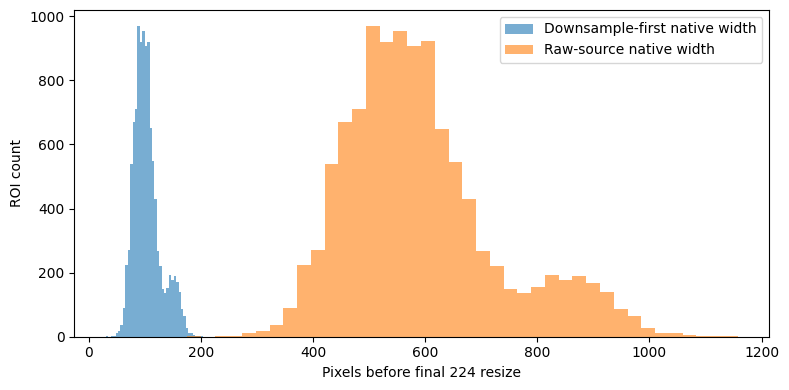

In [5]:
sizes=new[['old_box_width','old_box_height','raw_box_width','raw_box_height']].describe(percentiles=[.1,.5,.9])
display(sizes)
sizes.to_csv(REPORT/'native_box_sizes.csv')
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(new.old_box_width,bins=40,alpha=.6,label='Downsample-first native width')
ax.hist(new.raw_box_width,bins=40,alpha=.6,label='Raw-source native width')
ax.set(xlabel='Pixels before final 224 resize',ylabel='ROI count'); ax.legend()
fig.tight_layout(); fig.savefig(REPORT/'native_widths.png',dpi=150); plt.show()

## 6. Inspect aligned old/new examples

Choose training examples across class and native-size strata. Selection is deterministic and does not depend on favorable model predictions. Labels are inherited source annotations, not verified diagnoses by the agent.

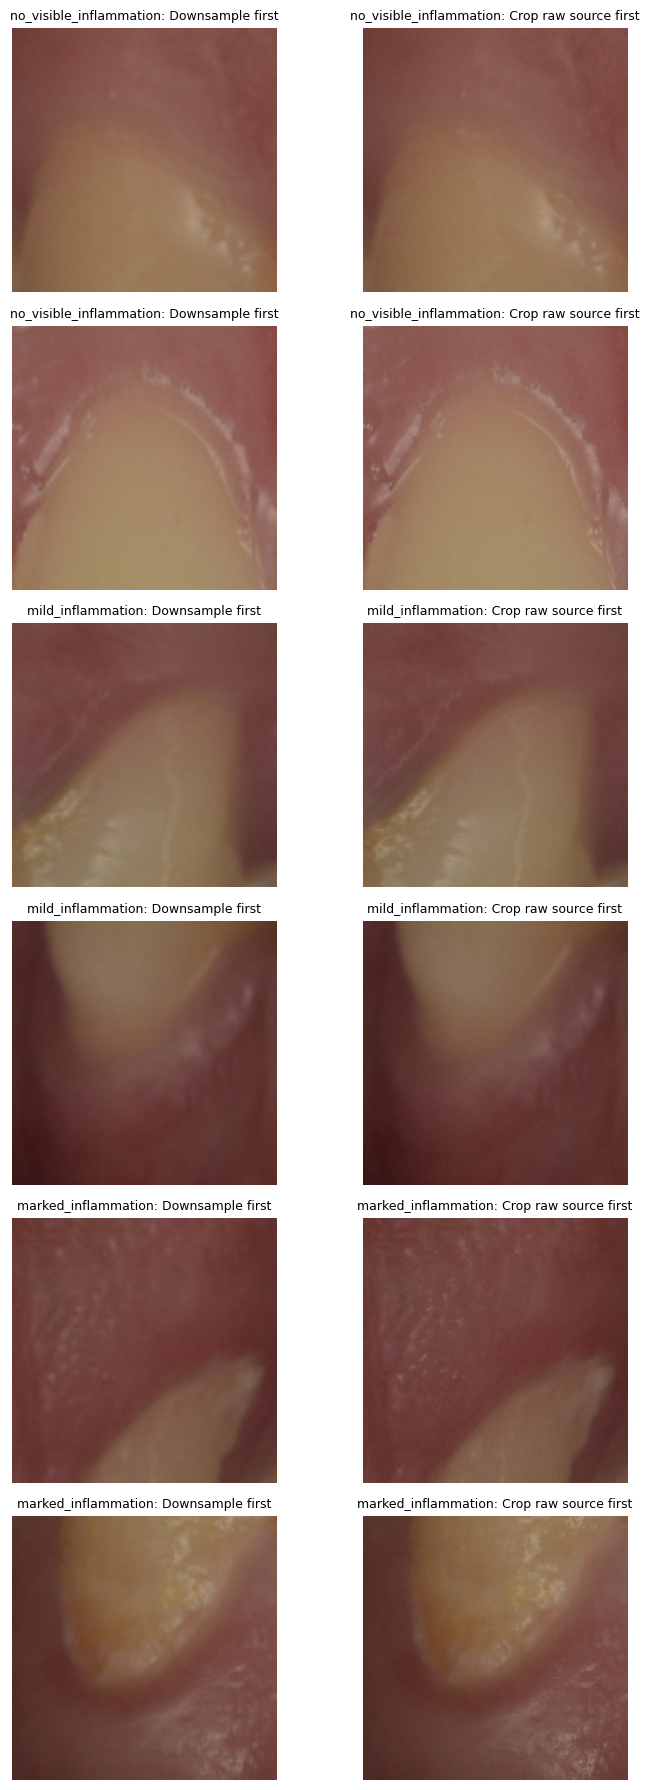

In [3]:
samples=[]
for class_id in range(3):
 frame=new[(new.split=='train') & (new.class_id==class_id)].sort_values('raw_box_width')
 samples.extend([frame.iloc[len(frame)//4],frame.iloc[3*len(frame)//4]])
fig,axes=plt.subplots(len(samples),2,figsize=(8,3*len(samples)))
for i,row in enumerate(samples):
 old_row=old.set_index('crop_id').loc[row.crop_id]
 for j,(base,path,title) in enumerate([(OLD_ROOT,old_row.local_path,'Downsample first'),(NEW_ROOT,row.local_path,'Crop raw source first')]):
  axes[i,j].imshow(Image.open(base/path)); axes[i,j].axis('off'); axes[i,j].set_title(f'{row.class_name}: {title}',fontsize=9)
fig.tight_layout(); fig.savefig(REPORT/'aligned_crop_examples.png',dpi=140); plt.show()

## 7. Describe image-detail strata without excluding cases

Compute edge-energy on a deterministic class-stratified train/validation sample. This is an image statistic, not a validated diagnostic quality score. Every image remains in the experiment.

In [7]:
quality=[]
for (_, _),group in new.groupby(['split','class_id']):
 for row in group.sample(n=min(60,len(group)),random_state=42).itertuples():
  item={'crop_id':row.crop_id,'split':row.split,'class_id':row.class_id}
  for name,base in [('old',OLD_ROOT),('raw',NEW_ROOT)]:
   with Image.open(base/row.local_path) as im:
    arr=np.asarray(im.convert('L'),dtype=float)
    lap=-4*arr[1:-1,1:-1]+arr[:-2,1:-1]+arr[2:,1:-1]+arr[1:-1,:-2]+arr[1:-1,2:]
    item[name+'_edge_variance']=float(lap.var())
  quality.append(item)
quality=pd.DataFrame(quality); quality.to_csv(REPORT/'detail_strata.csv',index=False)
display(quality.groupby('class_id')[['old_edge_variance','raw_edge_variance']].median())

,old_edge_variance,raw_edge_variance
class_id,,
0,3.109528,16.853360
1,3.520125,19.579682
2,3.752635,19.148533


## 8. Inspect recurrent validation errors

Use saved predictions only and join them to parent IDs. Errors shared by all four methods are useful review cases, but cannot justify clinical relabeling or dropping validation images.

wrong_models,0,1,2,3,4
class_name,,,,,
marked_inflammation,636,129,81,45,48
mild_inflammation,180,196,183,165,208
no_visible_inflammation,7,10,7,10,15


Validation parents: 160 ; ROI observations are not independent patients.


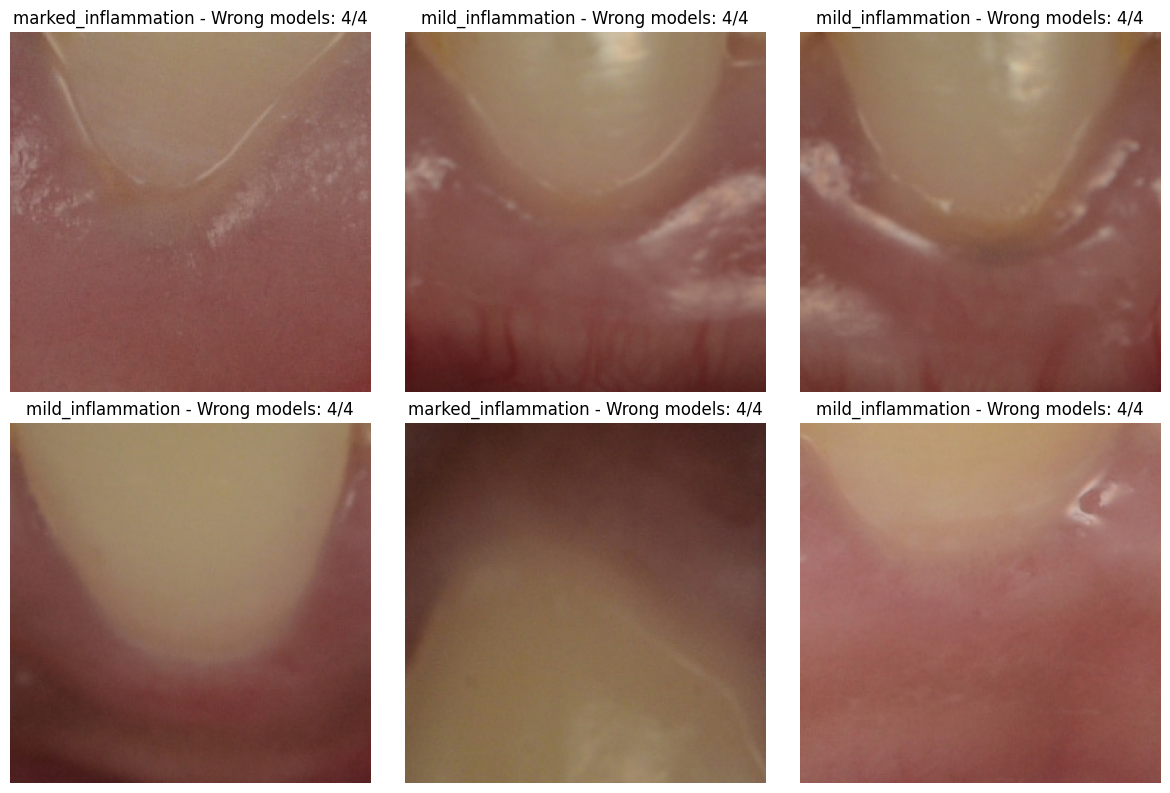

In [8]:
tables=[]
for path in sorted((ROOT/'data/runs').glob('ROI_07_*_v1/dentalselfie_07/*/validation_predictions.csv')):
 t=pd.read_csv(path); tables.append(t.set_index('crop_id').predicted_class.rename(path.parent.name))
errors=pd.concat(tables,axis=1).join(new.set_index('crop_id')[['parent_id','class_id','class_name','split']])
assert (errors.split=='val').all()
model_columns=[t.name for t in tables]
errors['wrong_models']=sum(errors[col]!=errors.class_id for col in model_columns)
errors.to_csv(REPORT/'cross_model_validation_errors.csv')
display(errors.groupby(['class_name','wrong_models']).size().unstack(fill_value=0))
print('Validation parents:',errors.parent_id.nunique(),'; ROI observations are not independent patients.')
review=errors.sort_values(['wrong_models'],ascending=False).head(6)
fig,axes=plt.subplots(2,3,figsize=(12,8))
lookup=new.set_index('crop_id')
for ax,(crop_id,row) in zip(axes.flat,review.iterrows()):
 ax.imshow(Image.open(NEW_ROOT/lookup.loc[crop_id,'local_path'])); ax.set_title(f'{row.class_name} - Wrong models: {row.wrong_models}/4'); ax.axis('off')
fig.tight_layout(); fig.savefig(REPORT/'recurrent_errors.png',dpi=140); plt.show()

## 9. Save the audit conclusion and training handoff

The raw-crop candidate is a new preparation version, not a replacement of historical ROI v1. The next experiments separately test preparation, objective and frozen representation. All use the locked sample membership.

In [9]:
summary={'status':'verified','manifest_sha256':receipt['manifest_sha256'],'crop_count':len(new),'parents':new.parent_id.nunique(),'test_images_opened':0,'same_membership':True,'clinical_relabeling':False,'quality_exclusions':0,'hypothesis':'Preserving native pixels before resizing may improve grading; training comparison pending.'}
(REPORT/'audit.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print(json.dumps(summary,indent=2))
print('Next: allowlisted Kaggle publication via notebook 02b, then independent 09.1/09.2/09.3 tracks.')

{
  "status": "verified",
  "manifest_sha256": "b9feaaceb4b9ea94ad540b553927ffb7f67e731098f7a78c770941804cbb4f06",
  "crop_count": 10889,
  "parents": 907,
  "test_images_opened": 0,
  "same_membership": true,
  "clinical_relabeling": false,
  "quality_exclusions": 0,
  "hypothesis": "Preserving native pixels before resizing may improve grading; training comparison pending."
}
Next: allowlisted Kaggle publication via notebook 02b, then independent 09.1/09.2/09.3 tracks.
